In [1]:
# Imports
library(dplyr)
library(survival)
library(splines)
library(nlme)
library(MASS)
install.packages("joineRML", repos = "https://cloud.r-project.org")
library(joineRML)
library(ggplot2)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘nlme’


The following object is masked from ‘package:dplyr’:

    collapse



Attaching package: ‘MASS’


The following object is masked from ‘package:dplyr’:

    select


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [29]:
zip(
  zipfile = "/kaggle/working/results.zip",
  files = "results",
  flags = "-r9X",
  extras = "-q"
)

In [2]:
# Stabilize the b_mode() optimization for dynamic predictions. Since random intercepts and random slopes 
# can have very different scales, the BFGS optimization can become unstable.Therefore, the random effects
# are scaled by their estimated standard deviations from D. Everything else stays unchanged.

b_mode_scaled <- function(theta, data) {

  sc <- sqrt(diag(as.matrix(theta$D)))

  # Sicherheitscheck
  sc[!is.finite(sc) | sc <= 0] <- 1

  optim(
    par = rep(0, sum(data$r)),
    fn = joineRML:::logpb,
    theta = theta,
    data = data,
    method = "BFGS",
    hessian = TRUE,
    control = list(
      fnscale = -1,
      parscale = sc
    )
  )
}

assignInNamespace("b_mode", b_mode_scaled, ns = "joineRML")

In [3]:
base_path <- "/kaggle/input/datasets/jonasmschl/data-lsr-3"
csv_path_train <- file.path(base_path, "data_joinerml_train")
csv_path_test <- file.path(base_path, "data_joinerml_test")
models_path <- "/kaggle/input/datasets/jonasmschl/data-lsr-3/2_censoring_models_joineRML"
results_path <- "/kaggle/working/results"

In [5]:
# Delete existing Results directory
if (dir.exists(results_path)) {
  unlink(results_path, recursive = TRUE, force = TRUE)
}

# Recreate empty Results directory
if (!dir.exists(results_path)) {
  dir.create(results_path, recursive = TRUE)
}

In [7]:
#HELPER Rebuild Brier Score fast from TransformerLSR

get_G_left <- function(x, censor_fit) {

  vapply(
    x,
    FUN.VALUE = numeric(1),
    FUN = function(z) {

      idx <- which(censor_fit$time < z)

      if (length(idx) == 0) {
        return(1)
      }

      censor_fit$surv[max(idx)]
    }
  )
}

brier_fast_r <- function(
  preds,
  events,
  times,
  censor_fit,
  LT,
  pred_times
) {

  events <- as.numeric(events)
  times <- as.numeric(times)
  pred_times <- as.numeric(pred_times)
  preds <- as.matrix(preds)

  n_patients <- length(events)
  n_times <- length(pred_times)

  # Check dimensions
  if (nrow(preds) != n_patients) {
    stop(
      "Number of rows in preds does not fit ",
      "with the count of patients."
    )
  }

  if (ncol(preds) != n_times) {
    stop(
      "Number of columns in preds does not fit ",
      "with the number of prediction times."
    )
  }

  # --------------------------------------------------
  # G(LT)
  # --------------------------------------------------

  G_LT <- summary(
    censor_fit,
    times = LT,
    extend = TRUE
  )$surv

  # --------------------------------------------------
  # G(T_i^-)
  # --------------------------------------------------

  G_times_minus <- get_G_left(
    x = times,
    censor_fit = censor_fit
  )

  G1_subject <- G_times_minus / G_LT

  G1 <- matrix(
    G1_subject,
    nrow = n_patients,
    ncol = n_times
  )

  # --------------------------------------------------
  # G(prediction_time)
  # --------------------------------------------------

  G_pred_times <- summary(
    censor_fit,
    times = pred_times,
    extend = TRUE
  )$surv

  G2_time <- G_pred_times / G_LT

  G2 <- matrix(
    G2_time,
    nrow = n_patients,
    ncol = n_times,
    byrow = TRUE
  )

  # --------------------------------------------------
  # Event, time, and prediction-horizon matrices
  # --------------------------------------------------

  event_mat <- matrix(
    events,
    nrow = n_patients,
    ncol = n_times
  )

  times_mat <- matrix(
    times,
    nrow = n_patients,
    ncol = n_times
  )

  pred_times_mat <- matrix(
    pred_times,
    nrow = n_patients,
    ncol = n_times,
    byrow = TRUE
  )

  # --------------------------------------------------
  # w1 and w2 like in Python-Code
  # --------------------------------------------------

  w1 <- (
    times_mat <= pred_times_mat &
      event_mat == 1
  ) * 1

  w2 <- (
    times_mat > pred_times_mat
  ) * 1
    
    cat("Seed:", seed, "\n")
    

    cat(
      "G1 == 0 und w1 == 0:",
      sum((G1 == 0) & (w1 == 0), na.rm = TRUE),
      "\n"
    )
    
    cat(
      "G1 == 0 und w1 == 1:",
      sum((G1 == 0) & (w1 == 1), na.rm = TRUE),
      "\n"
    )
    
    cat(
      "G2 == 0 und w2 == 0:",
      sum((G2 == 0) & (w2 == 0), na.rm = TRUE),
      "\n"
    )
    
    cat(
      "G2 == 0 und w2 == 1:",
      sum((G2 == 0) & (w2 == 1), na.rm = TRUE),
      "\n"
    )
    problem_G1_inactive <- apply(
        (G1 == 0) & (w1 == 0),
        1,
        any,
        na.rm = TRUE
    )
    cat(
     "Patienten mit G1 == 0 und w1 == 0:",
      sum(problem_G1_inactive),
     "\n"
    )
    
  # --------------------------------------------------
  # Brier Scores
  # --------------------------------------------------
  term1 <- matrix(
    0,
    nrow = n_patients,
    ncol = n_times
  )

  term2 <- matrix(
    0,
    nrow = n_patients,
    ncol = n_times
  )

  idx1 <- w1 == 1
  idx2 <- w2 == 1

  term1[idx1] <- preds[idx1]^2 / G1[idx1]

  term2[idx2] <- (
    (1 - preds[idx2])^2 /
      G2[idx2]
  )

  score_mat <- term1 + term2

  brier_scores <- colMeans(
    score_mat,
    na.rm = FALSE
  )

  data.frame(
    prediction_time = pred_times,
    brier_score = brier_scores
  )
}

In [17]:
# Check for right files
list.files(models_path)

[1] "mjoint_fit_seed_1_with_num_100_and_timeout_1000_missing.rds"  
  [2] "mjoint_fit_seed_10_with_num_100_and_timeout_1000_missing.rds" 
  [3] "mjoint_fit_seed_100_with_num_100_and_timeout_1000_missing.rds"
  [4] "mjoint_fit_seed_11_with_num_100_and_timeout_1000_missing.rds" 
  [5] "mjoint_fit_seed_12_with_num_100_and_timeout_1000_missing.rds" 
  [6] "mjoint_fit_seed_13_with_num_100_and_timeout_1000_missing.rds" 
  [7] "mjoint_fit_seed_14_with_num_100_and_timeout_1000_missing.rds" 
  [8] "mjoint_fit_seed_15_with_num_100_and_timeout_1000_missing.rds" 
  [9] "mjoint_fit_seed_16_with_num_100_and_timeout_1000_missing.rds" 
 [10] "mjoint_fit_seed_17_with_num_100_and_timeout_1000_missing.rds" 
 [11] "mjoint_fit_seed_18_with_num_100_and_timeout_1000_missing.rds" 
 [12] "mjoint_fit_seed_19_with_num_100_and_timeout_1000_missing.rds" 
 [13] "mjoint_fit_seed_2_with_num_100_and_timeout_1000_missing.rds"  
 [14] "mjoint_fit_seed_20_with_num_100_and_timeout_1000_missing.rds" 
 [15] "mjoint_fit_seed_21_with_num_100_and_timeout_1000_missing.rds" 
 [16] "mjoint_fit_seed_22_with_num_100_and_timeout_1000_missing.rds" 
 [17] "mjoint_fit_seed_23_with_num_100_and_timeout_1000_missing.rds" 
 [18] "mjoint_fit_seed_24_with_num_100_and_timeout_1000_missing.rds" 
 [19] "mjoint_fit_seed_25_with_num_100_and_timeout_1000_missing.rds" 
 [20] "mjoint_fit_seed_26_with_num_100_and_timeout_1000_missing.rds" 
 [21] "mjoint_fit_seed_27_with_num_100_and_timeout_1000_missing.rds" 
 [22] "mjoint_fit_seed_28_with_num_100_and_timeout_1000_missing.rds" 
 [23] "mjoint_fit_seed_29_with_num_100_and_timeout_1000_missing.rds" 
 [24] "mjoint_fit_seed_3_with_num_100_and_timeout_1000_missing.rds"  
 [25] "mjoint_fit_seed_30_with_num_100_and_timeout_1000_missing.rds" 
 [26] "mjoint_fit_seed_31_with_num_100_and_timeout_1000_missing.rds" 
 [27] "mjoint_fit_seed_32_with_num_100_and_timeout_1000_missing.rds" 
 [28] "mjoint_fit_seed_33_with_num_100_and_timeout_1000_missing.rds" 
 [29] "mjoint_fit_seed_34_with_num_100_and_timeout_1000_missing.rds" 
 [30] "mjoint_fit_seed_35_with_num_100_and_timeout_1000_missing.rds" 
 [31] "mjoint_fit_seed_36_with_num_100_and_timeout_1000_missing.rds" 
 [32] "mjoint_fit_seed_37_with_num_100_and_timeout_1000_missing.rds" 
 [33] "mjoint_fit_seed_38_with_num_100_and_timeout_1000_missing.rds" 
 [34] "mjoint_fit_seed_39_with_num_100_and_timeout_1000_missing.rds" 
 [35] "mjoint_fit_seed_4_with_num_100_and_timeout_1000_missing.rds"  
 [36] "mjoint_fit_seed_40_with_num_100_and_timeout_1000_missing.rds" 
 [37] "mjoint_fit_seed_41_with_num_100_and_timeout_1000_missing.rds" 
 [38] "mjoint_fit_seed_42_with_num_100_and_timeout_1000_missing.rds" 
 [39] "mjoint_fit_seed_43_with_num_100_and_timeout_1000_missing.rds" 
 [40] "mjoint_fit_seed_44_with_num_100_and_timeout_1000_missing.rds" 
 [41] "mjoint_fit_seed_45_with_num_100_and_timeout_1000_missing.rds" 
 [42] "mjoint_fit_seed_46_with_num_100_and_timeout_1000_missing.rds" 
 [43] "mjoint_fit_seed_47_with_num_100_and_timeout_1000_missing.rds" 
 [44] "mjoint_fit_seed_48_with_num_100_and_timeout_1000_missing.rds" 
 [45] "mjoint_fit_seed_49_with_num_100_and_timeout_1000_missing.rds" 
 [46] "mjoint_fit_seed_5_with_num_100_and_timeout_1000_missing.rds"  
 [47] "mjoint_fit_seed_50_with_num_100_and_timeout_1000_missing.rds" 
 [48] "mjoint_fit_seed_51_with_num_100_and_timeout_1000_missing.rds" 
 [49] "mjoint_fit_seed_52_with_num_100_and_timeout_1000_missing.rds" 
 [50] "mjoint_fit_seed_53_with_num_100_and_timeout_1000_missing.rds" 
 [51] "mjoint_fit_seed_54_with_num_100_and_timeout_1000_missing.rds" 
 [52] "mjoint_fit_seed_55_with_num_100_and_timeout_1000_missing.rds" 
 [53] "mjoint_fit_seed_56_with_num_100_and_timeout_1000_missing.rds" 
 [54] "mjoint_fit_seed_57_with_num_100_and_timeout_1000_missing.rds" 
 [55] "mjoint_fit_seed_58_with_num_100_and_timeout_1000_missing.rds" 
 [56] "mjoint_fit_seed_59_with_num_100_and_timeout_1000_missing.rds" 
 [57] "mjoint_fit_seed_6_with_num_100_and_timeout_1000_missing.rds"  
 [58] "mjoin

In [9]:
# Set variables
num_traj = 100 # Number of patients
timeout = 1000 # Max visits
num_sim = 100

In [10]:
# Load test and train data for evaluation
files_test <- paste0(
  "DIVAT_sim_missing_test_", num_traj,
  "_visit_", timeout,
  "_long_3_seed_", 1:num_sim,
  ".csv"
)

files_test_list <- lapply(
  file.path(csv_path_test, files_test),
  read.csv
)

files_train <- paste0(
  "DIVAT_sim_missing_train_", num_traj,
  "_visit_", timeout,
  "_long_3_seed_", 1:num_sim,
  ".csv"
)

files_train_list <- lapply(
  file.path(csv_path_train, files_train),
  read.csv
)

In [11]:
# Prepare data
prepare_data <- function(df) {
  df_ready <- df %>%
    dplyr::select(id, obstime, time, event, Y1, Y2, Y3, X1, X2, X3) %>%
    dplyr::arrange(id, obstime) %>%
    dplyr::group_by(id) %>%
    dplyr::mutate(
      event = ifelse(event == "True", 1, 0)
    ) %>%
    dplyr::ungroup()

  return(df_ready)
}

test_prepared <- lapply(
  files_test_list,
  prepare_data
)

train_prepared <- lapply(
  files_train_list,
  prepare_data
)

In [12]:
# Get all the longitudinal results for all seeds
long_results <- list()

for (seed in seq_len(num_sim)) {

    test_data <- test_prepared[[seed]]
    test_ids <- unique(test_data$id)
    seed_long_results <- list()
    fit <- readRDS(file.path(models_path, paste0("mjoint_fit_seed_", seed,
                                            "_with_num_", num_traj, "_and_timeout_", timeout, "_missing.rds")))
    
    for (pid in test_ids) {
      
      one_subject <- test_data %>%
        dplyr::filter(id == pid) %>%
        dplyr::arrange(obstime)
      
      n_visits <- nrow(one_subject)
      
      if (n_visits < 2) next
      
      for (j in 2:n_visits) {

        # Prepare data for joineRML for each long. outcome
        history <- one_subject[1:(j - 1), , drop = FALSE]
        next_row <- one_subject[j, ]
        prediction_time <- next_row$obstime

        history_Y1 <- history %>%
            dplyr::filter(!is.na(Y1))

        history_Y2 <- history %>%
            dplyr::filter(!is.na(Y2))

        history_Y3 <- history %>%
            dplyr::filter(!is.na(Y3))
        
        if (
           nrow(history_Y1) == 0 ||
           nrow(history_Y2) == 0 ||
           nrow(history_Y3) == 0
        ) next

        # Prediction
        pred <- tryCatch(
          dynLong(fit, newdata = list(history_Y1, history_Y2, history_Y3), u = prediction_time),
          error = function(e) NULL
        )
        
        if (is.null(pred)) next
        
        seed_long_results[[length(seed_long_results) + 1]] <- data.frame(
          seed = seed,
          id = pid,
          visit_index = j,
          obstime = prediction_time,
          outcome = c("Y1", "Y2", "Y3"),
          predicted = c(pred$pred$Y1$y.pred, pred$pred$Y2$y.pred, pred$pred$Y3$y.pred),
          true = c(next_row$Y1, next_row$Y2, next_row$Y3)
        )
      }
    }

    # Save results
    long_results[[seed]] <- dplyr::bind_rows(seed_long_results)
    
    file_name <- paste0("long_results_seed_", seed,
                    "_with_num_", num_traj, "_and_timeout_", timeout, "_missing.rds")
    saveRDS(long_results[[seed]], file = file.path(results_path, file_name))

    cat("\n========== Seed:", seed, "==========\n")
    print(head(long_results[[seed]][, c("id", "visit_index", "outcome", "true", "predicted")], 9))

    rm(fit, test_data, test_ids, seed_long_results)
    gc()
}


========== Seed: 1 ==========
  id visit_index outcome     true predicted
1 80           2      Y1 3.455905  2.577950
2 80           2      Y2 6.725900  6.118019
3 80           2      Y3 2.481950  2.416355
4 80           3      Y1 3.434694  3.158610
5 80           3      Y2 6.714558  6.932793
6 80           3      Y3 2.629658  2.643610
7 80           4      Y1 3.587396  3.355996
8 80           4      Y2       NA  7.174798
9 80           4      Y3 1.970827  2.679897

========== Seed: 2 ==========
  id visit_index outcome     true predicted
1 80           2      Y1 3.042768  2.330852
2 80           2      Y2 6.546179  5.520067
3 80           2      Y3 2.484582  2.121132
4 81           2      Y1       NA  2.152123
5 81           2      Y2 6.183404  5.300088
6 81           2      Y3 2.217150  2.078519
7 81           3      Y1 2.794423  2.557248
8 81           3      Y2 6.386313  6.040453
9 81           3      Y3 2.291289  2.205270

========== Seed: 3 ==========
  id visit_index outcome   

In [19]:
# Load data
long_results <- vector("list", num_sim)

for (seed in seq_len(num_sim)) {

  file_name <- paste0(
    "long_results_seed_", seed,
    "_with_num_", num_traj,
    "_and_timeout_", timeout,
    "_missing.rds"
  )

  long_results[[seed]] <- readRDS(
    file.path(results_path, file_name)
  )
}

In [15]:
# Check if data is plausible

# Combine results from all seeds
long_results_all <- dplyr::bind_rows(long_results)

# Show first 30 predictions
print(head(long_results_all, 30))

# Summary of predictions by seed and outcome
prediction_summary <- long_results_all %>%
  dplyr::group_by(seed, outcome) %>%
  dplyr::summarise(
    n_predictions = dplyr::n(),
    n_valid = sum(!is.na(predicted) & !is.na(true)),
    mean_predicted = mean(predicted, na.rm = TRUE),
    mean_true = mean(true, na.rm = TRUE),
    .groups = "drop"
  )

print(prediction_summary, n = Inf)

# Inspect prediction errors
prediction_errors <- long_results_all %>%
  dplyr::filter(!is.na(predicted), !is.na(true)) %>%
  dplyr::mutate(
    error = predicted - true,
    squared_error = error^2
  ) %>%
  dplyr::arrange(dplyr::desc(squared_error))

print(head(prediction_errors, 20))

   seed id visit_index   obstime outcome predicted     true
1     1 80           2  529.4064      Y1  2.577950 3.455905
2     1 80           2  529.4064      Y2  6.118019 6.725900
3     1 80           2  529.4064      Y3  2.416355 2.481950
4     1 80           3  730.8977      Y1  3.158610 3.434694
5     1 80           3  730.8977      Y2  6.932793 6.714558
6     1 80           3  730.8977      Y3  2.643610 2.629658
7     1 80           4  873.7552      Y1  3.355996 3.587396
8     1 80           4  873.7552      Y2  7.174798       NA
9     1 80           4  873.7552      Y3  2.679897 1.970827
10    1 80           5 1001.0113      Y1  3.508054       NA
11    1 80           5 1001.0113      Y2  7.369810 6.721102
12    1 80           5 1001.0113      Y3  2.678722 2.597068
13    1 80           6 1056.5255      Y1  3.481279 3.584875
14    1 80           6 1056.5255      Y2  7.246832       NA
15    1 80           6 1056.5255      Y3  2.651521 2.596025
16    1 80           7 1157.0251      Y1

In [20]:
# Bulding RSME tables with mean and sd over all seeds
rmse_tables <- lapply(long_results, function(seed_long_results) {
  seed_long_results %>%
    dplyr::filter(
      !is.na(predicted),
      !is.na(true)
    ) %>%
    dplyr::group_by(outcome) %>%
    dplyr::summarise(
      n = dplyr::n(),
      RMSE = sqrt(mean((predicted - true)^2)),
      .groups = "drop"
    )
})

rmse_by_seed <- dplyr::bind_rows(
  rmse_tables,
  .id = "seed"
)

rmse_summary <- rmse_by_seed %>%
  dplyr::group_by(outcome) %>%
  dplyr::summarise(
    n_seeds = sum(!is.na(RMSE)),
    mean_RMSE = mean(RMSE, na.rm = FALSE),
    sd_RMSE = sd(RMSE, na.rm = FALSE),
    .groups = "drop"
  )

rmse_summary

outcome,n_seeds,mean_RMSE,sd_RMSE
<chr>,<int>,<dbl>,<dbl>
Y1,100,0.2650281,0.03094556
Y2,100,0.4005530,0.04816177
Y3,100,0.3203751,0.01787066



========== Patient 80 ==========


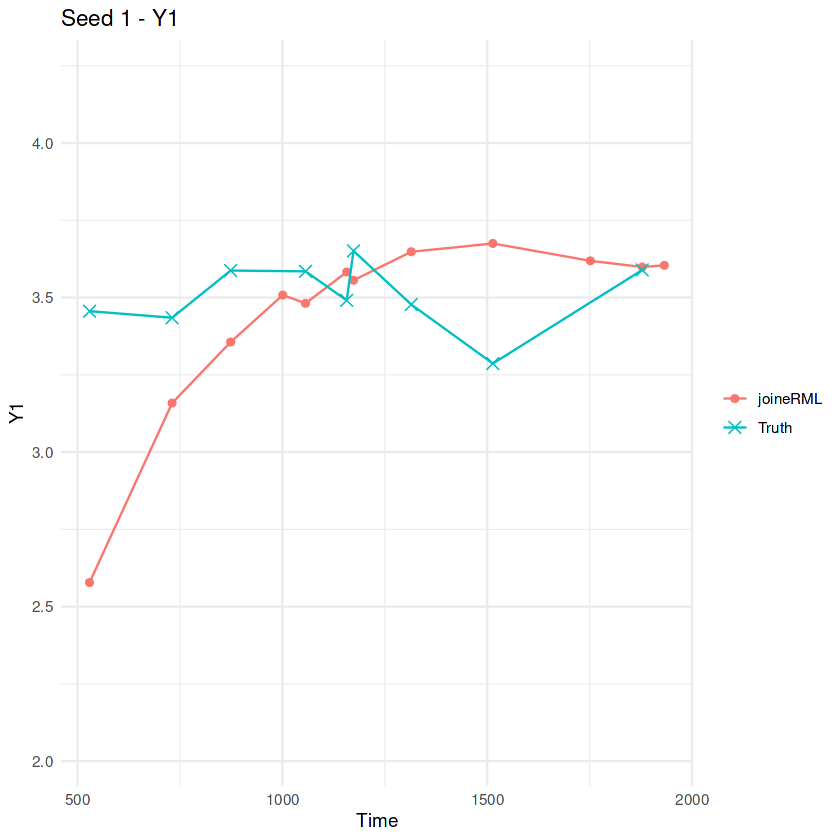

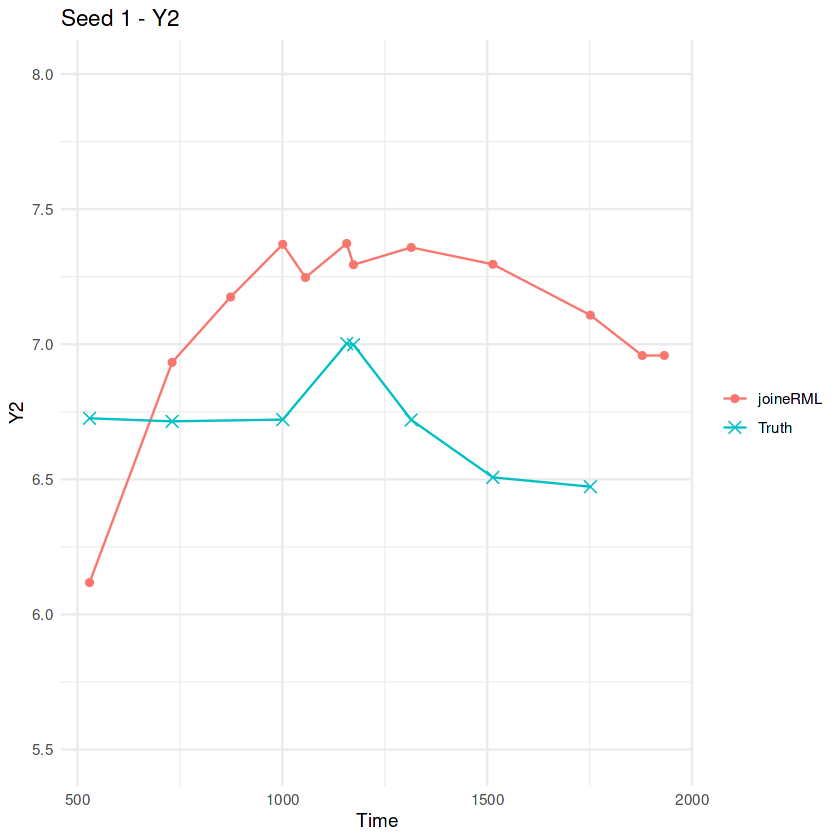


========== Patient 80 ==========


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?
`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


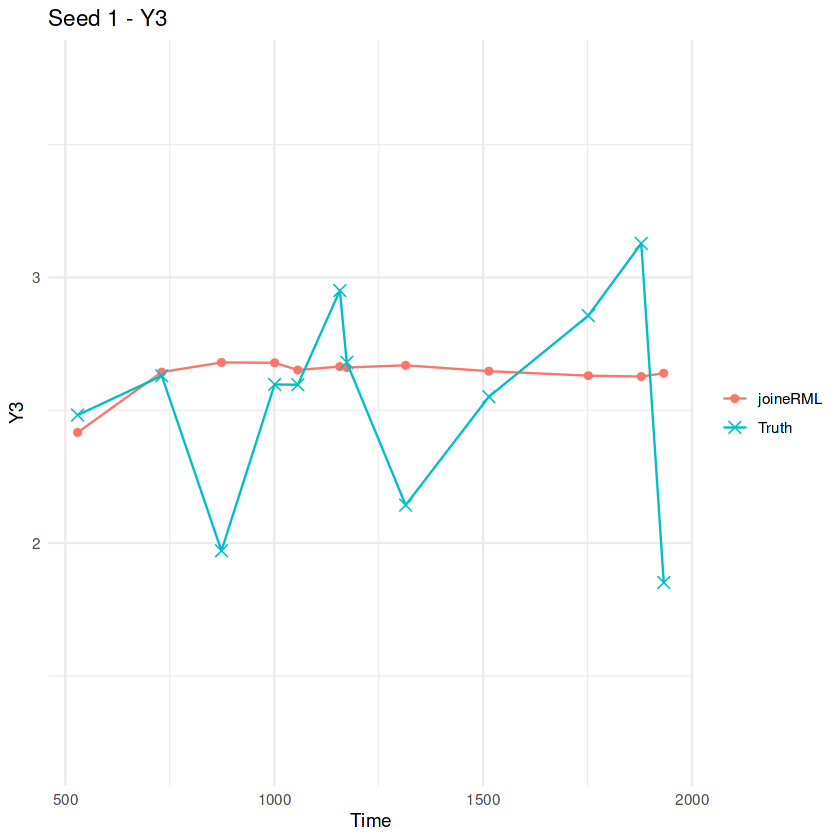

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?
`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


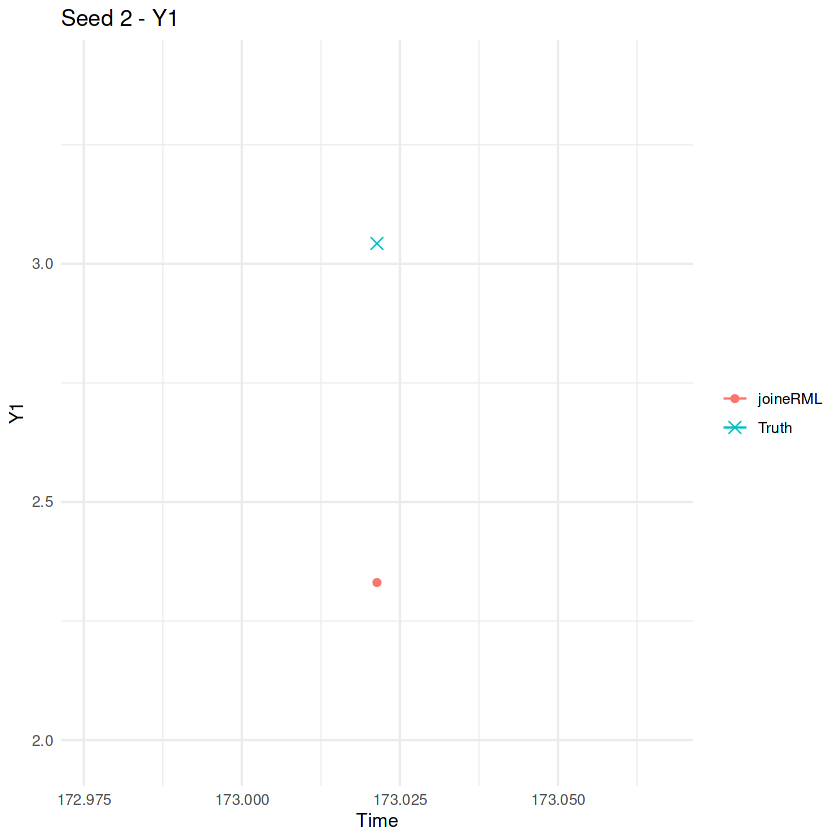

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?
`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


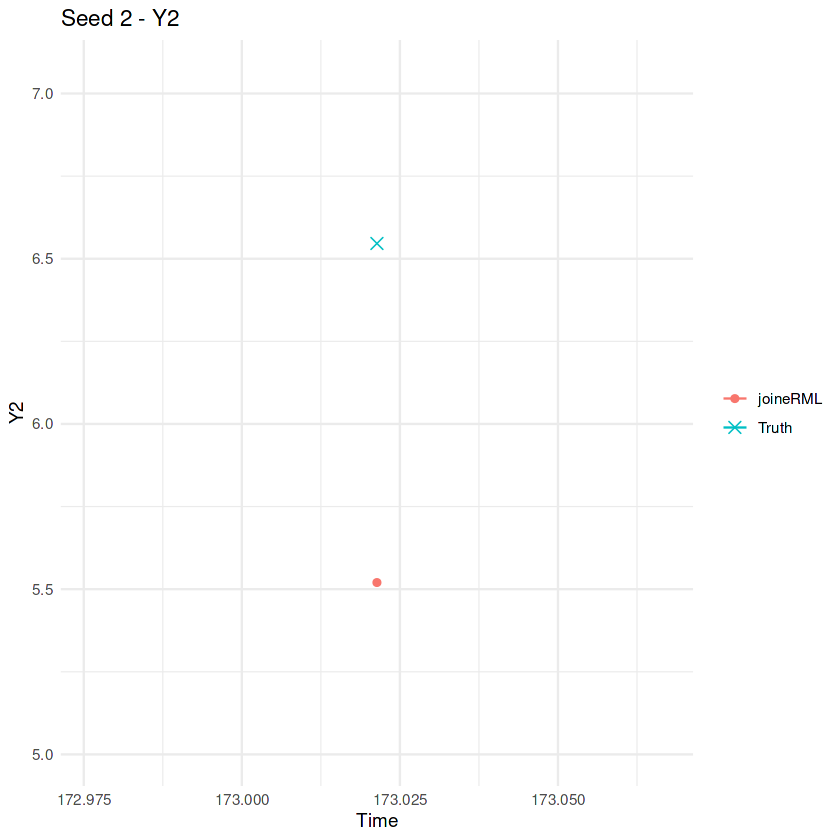


========== Patient 80 ==========


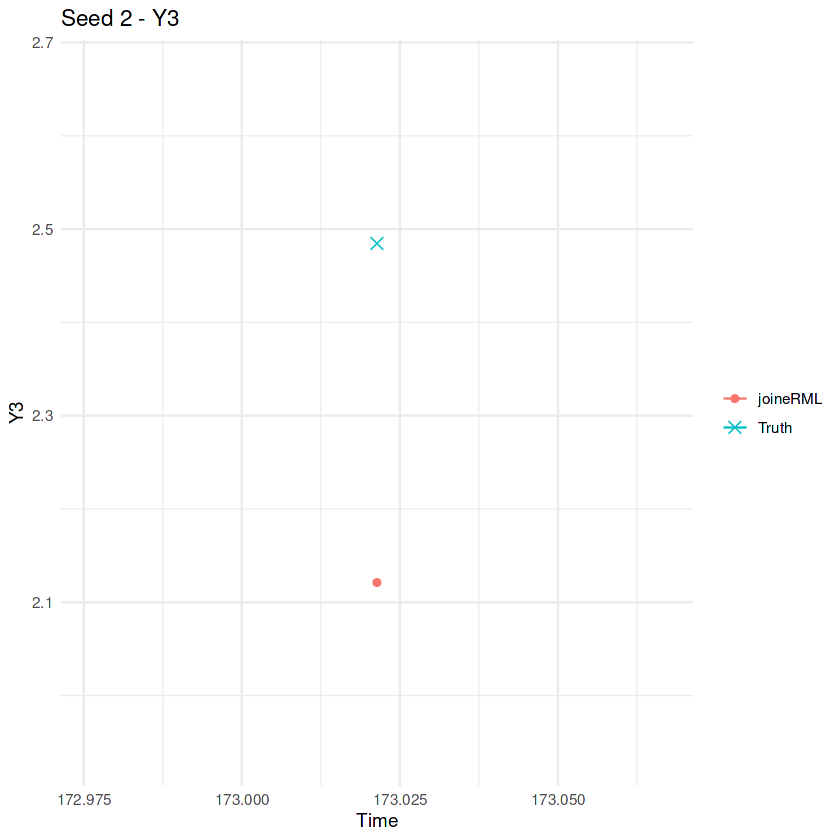

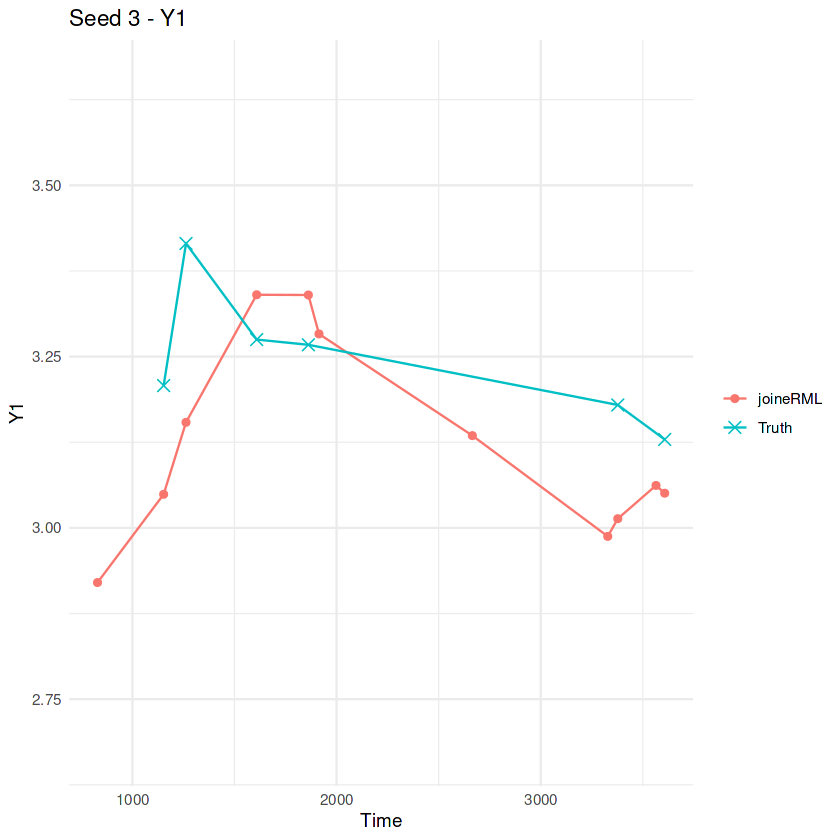

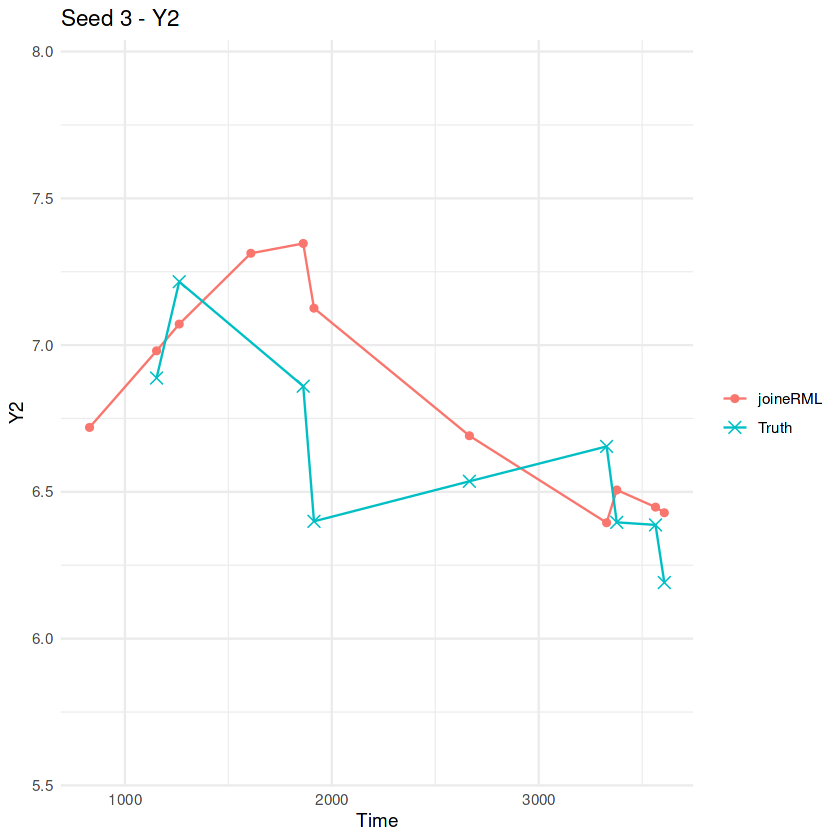


========== Patient 80 ==========


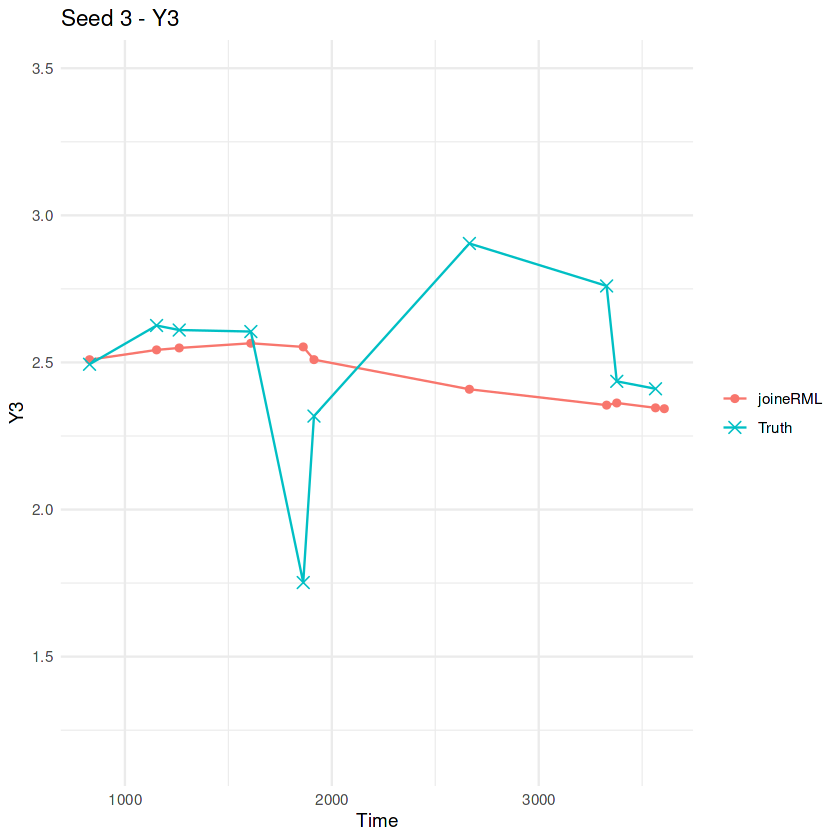

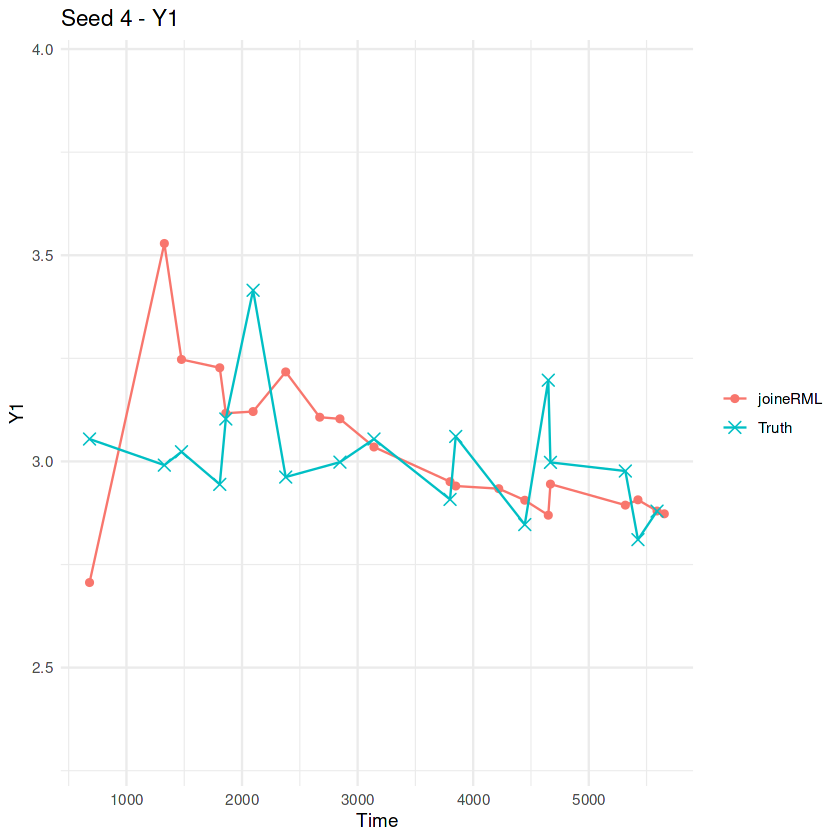

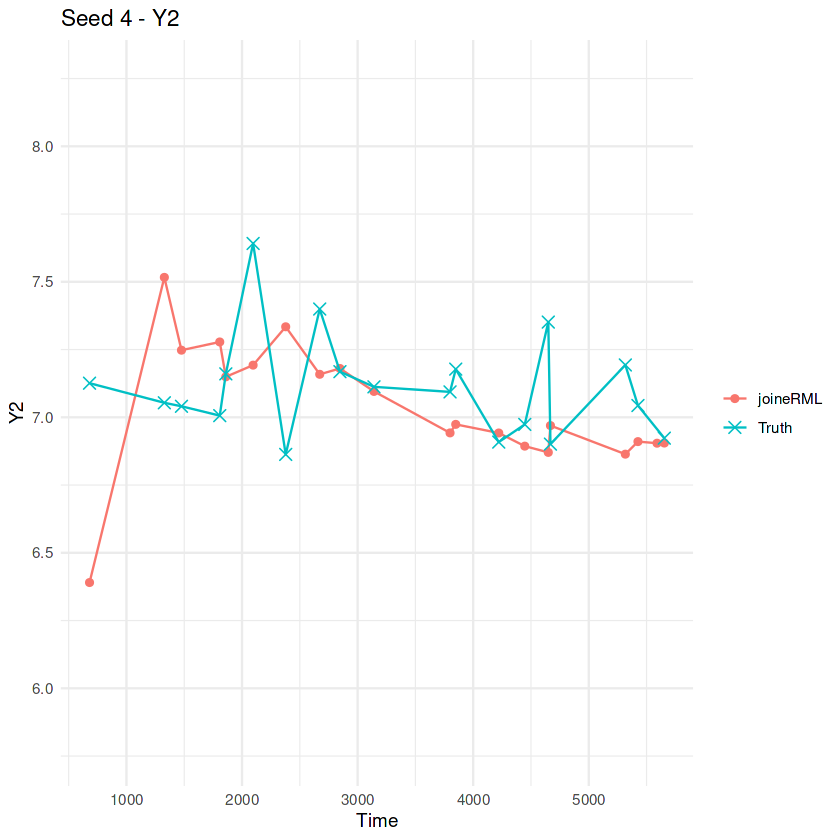


========== Patient 80 ==========


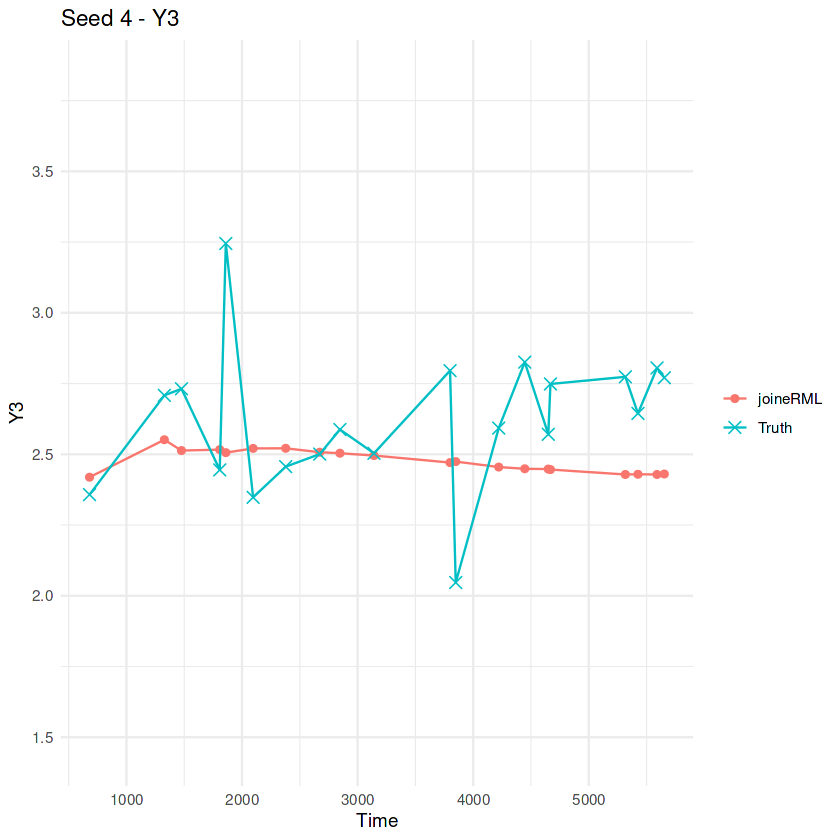

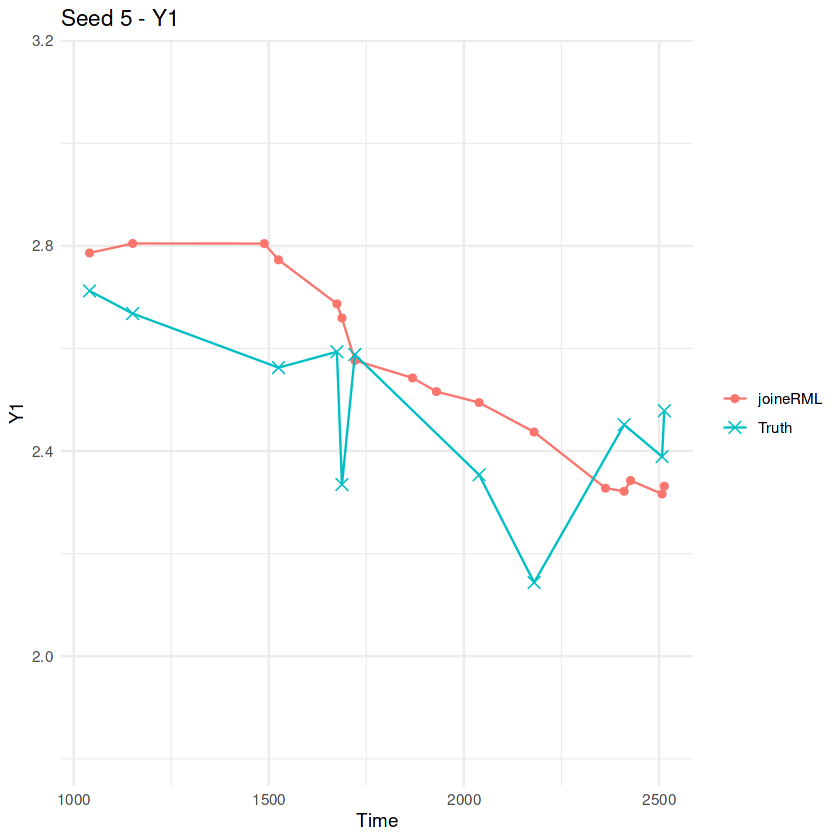

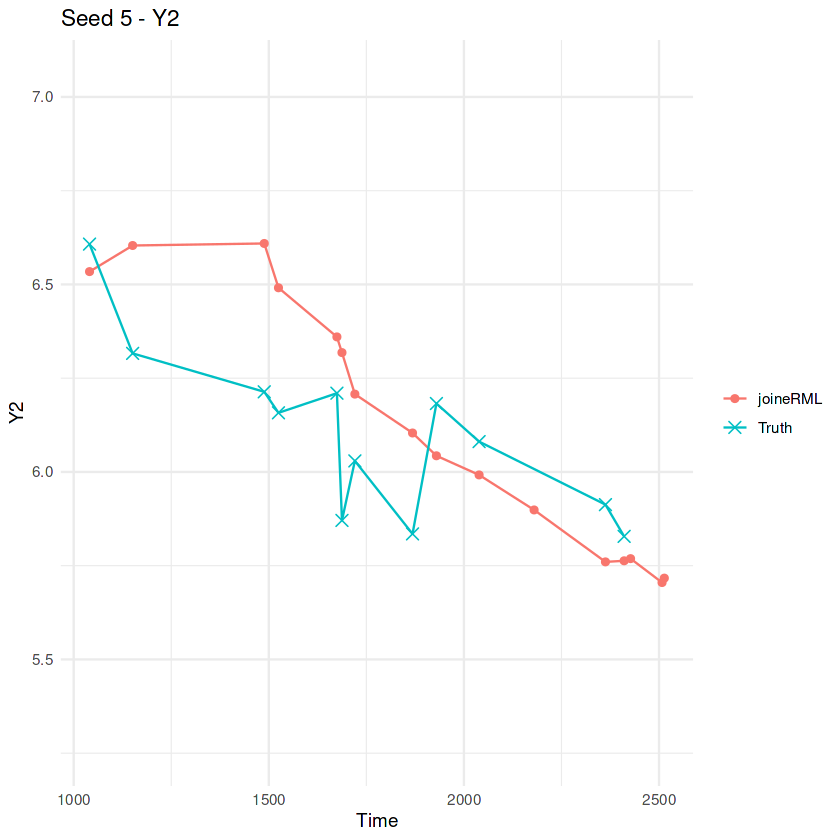

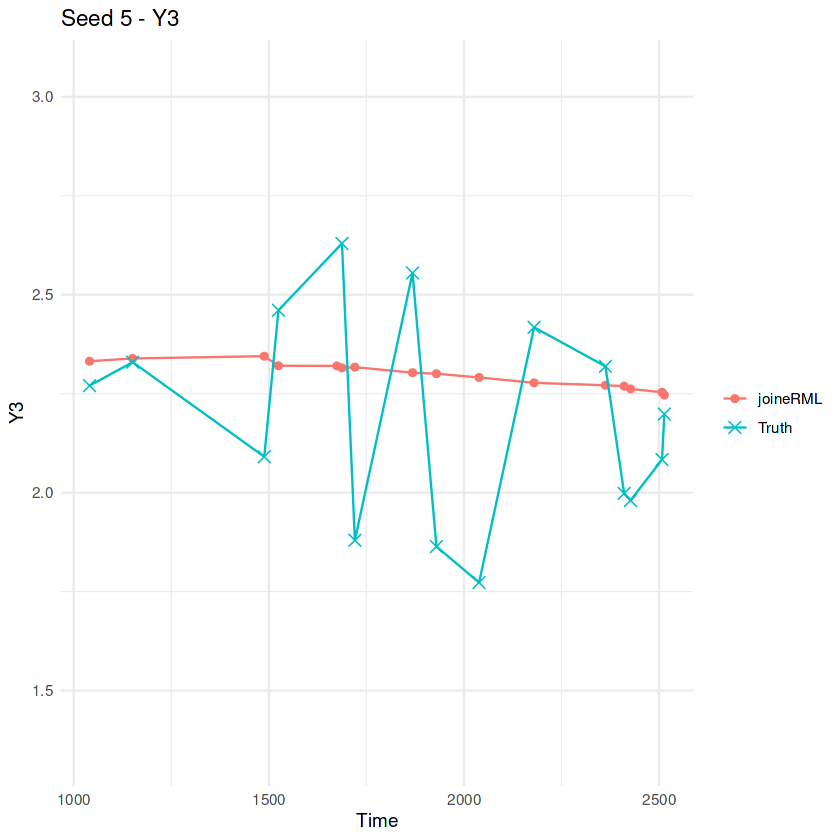

In [21]:
# Plot longitudinal data
for (seed in seq_len(5)) {

  plot_data <- long_results[[seed]]

  # erster Testpatient mit vorhandenen Predictions
  pid <- unique(plot_data$id)[1]
  cat("\n========== Patient", pid, "==========\n")

  patient_data <- plot_data %>%
    filter(id == pid)

  for (y in c("Y1", "Y2", "Y3")) {

    plot_y <- patient_data %>%
      filter(outcome == y) %>%
      arrange(obstime)

    # Y-Achse etwas erweitern
    all_values <- c(
      plot_y$predicted,
      plot_y$true[!is.na(plot_y$true)]
    )

    y_min <- min(all_values, na.rm = TRUE)
    y_max <- max(all_values, na.rm = TRUE)
    margin <- 0.5 * (y_max - y_min)

    p <- ggplot(plot_y, aes(x = obstime)) +

      # joineRML Prediction
      geom_line(
        aes(y = predicted, color = "joineRML")
      ) +
      geom_point(
        aes(y = predicted, color = "joineRML")
      ) +

      # Truth nur für beobachtete Werte
      geom_line(
        data = plot_y %>% filter(!is.na(true)),
        aes(y = true, color = "Truth")
      ) +
      geom_point(
        data = plot_y %>% filter(!is.na(true)),
        aes(y = true, color = "Truth"),
        shape = 4,
        size = 3
      ) +

      coord_cartesian(
        ylim = c(y_min - margin, y_max + margin)
      ) +

      labs(
        x = "Time",
        y = y,
        title = paste0("Seed ", seed, " - ", y),
        color = NULL
      ) +

      theme_minimal()

    print(p)
  }
}

In [23]:
# Save results additionally as CSV
for (seed in seq_len(5)) {

    file_name <- paste0(
        "long_results_seed_", seed, ".csv"
    )

    write.csv(
        long_results[[seed]],
        file.path(results_path, file_name),
        row.names = FALSE
    )
}

In [24]:
# Get brier score and ibs over all seeds
surv_results <- list()
brier_results <- list()
ibs_results <- list()
excluded_seeds <- integer(0)

pred_window_length <- 6

for (seed in seq_len(100)) {

  train_data <- train_prepared[[seed]]
  test_data <- test_prepared[[seed]]
  fit <- readRDS(file.path(models_path, paste0("mjoint_fit_seed_", seed,
                                            "_with_num_", num_traj, "_and_timeout_", timeout, "_missing.rds")))

  seed_surv_results <- list()

  # Landmark-time and prediction times
  train_surv_times <- train_data %>%
    dplyr::distinct(id, .keep_all = TRUE) %>%
    dplyr::pull(time)

  LT <- quantile(
    train_surv_times,
    probs = 0.10,
    names = FALSE
  )

  pred_times <- quantile(
    train_surv_times,
    probs = seq(
      0.10,
      0.90,
      length.out = pred_window_length + 1
    ),
    names = FALSE
  )[-1]

  pred_times <- as.numeric(pred_times)

  last_failure_time <- train_data %>%
    dplyr::distinct(id, time, event) %>%
    dplyr::filter(event == 1) %>%
    dplyr::summarise(last_failure = max(time)) %>%
    dplyr::pull(last_failure)
   
  if (any(pred_times > last_failure_time)) {
    excluded_seeds <- c(excluded_seeds, seed)
    warning(paste(
      "Seed", seed,
      "excluded: Prediction time exceeds last failure time."
    ))
    next
  }

  # Check: Landmark and predction times 
  cat("\n----------------------------------------\n")
  cat("Seed:", seed, "\n")
  cat("Number of patients for training:", length(train_surv_times), "\n")
  cat("LT:", LT, "\n")
  cat("pred_times:", paste(round(pred_times, 3), collapse = ", "), "\n")
  cat("pred_times[1] - LT:", pred_times[1] - LT, "\n")
  cat("All pred_times > LT:", all(pred_times > LT), "\n")
  cat("----------------------------------------\n")

  # Eligible patient ids 
  eligible_ids <- test_data %>%
    dplyr::distinct(id, time, event) %>%
    dplyr::filter(time > LT) %>%
    dplyr::pull(id)


  # Get survival predictions
  for (pid in eligible_ids) {

    one_subject <- test_data %>%
      dplyr::filter(id == pid) %>%
      dplyr::arrange(obstime)

    # Only long. info up to landmark time
    history <- one_subject %>%
      dplyr::filter(obstime <= LT)

    history_Y1 <- history %>%
      dplyr::filter(!is.na(Y1))

    history_Y2 <- history %>%
      dplyr::filter(!is.na(Y2))

    history_Y3 <- history %>%
      dplyr::filter(!is.na(Y3))

    if (
      nrow(history_Y1) == 0 ||
      nrow(history_Y2) == 0 ||
      nrow(history_Y3) == 0
    ) {
      next
    }

    subject_time <- one_subject$time[1]
    subject_event <- one_subject$event[1]
    
    # last observed time
    last_obs_time <- max(
      max(history_Y1$obstime),
      max(history_Y2$obstime),
      max(history_Y3$obstime)
    )
    
    # Survival-probability up to LT relativly zum letzten Beobachtungszeitpunkt
    if (last_obs_time < LT) {
    
      pred_surv_LT <- tryCatch(
        dynSurv(
          object = fit,
          newdata = list(history_Y1, history_Y2, history_Y3),
          u = LT
        ),
        error = function(e) {
          print(e$message)
          NULL
        }
      )
    
      if (is.null(pred_surv_LT)) {
        cat("Patient", pid, "skipped: dynSurv at LT failed\n")
        next
      }
    
      surv_LT <- as.numeric(pred_surv_LT$pred$surv)
    
    } else {
    
      # In case the last time is landmark time
      surv_LT <- 1
    }
    
    # Predictions
    for (prediction_time in pred_times) {
    
      pred_surv <- tryCatch(
        dynSurv(
          object = fit,
          newdata = list(history_Y1, history_Y2, history_Y3),
          u = prediction_time
        ),
        error = function(e) {
          print(e$message)
          NULL
        }
      )
    
      if (is.null(pred_surv)) {
        cat("Patient", pid, "skipped: dynSurv failed\n")
        next
      }
    
      surv_u <- as.numeric(pred_surv$pred$surv)
    
      # Cond. surivival prediction to account for survival up to LT
      predicted_survival <- surv_u / surv_LT
    
      seed_surv_results[[length(seed_surv_results) + 1]] <-
        data.frame(
          seed = seed,
          id = pid,
          LT = LT,
          prediction_time = prediction_time,
          time = subject_time,
          event = subject_event,
          predicted_survival = predicted_survival
        )
    }
  }


  # Results calc.
  seed_surv_df <- dplyr::bind_rows(seed_surv_results)

  if (nrow(seed_surv_df) == 0) {
    warning(
      paste("For seed", seed, "no survival predictions were generated.")
    )
    next
  }

  # Patient information matching the prediction-horizon
  prediction_subjects <- seed_surv_df %>%
    dplyr::distinct(id, time, event) %>%
    dplyr::arrange(id)

  # Matrix for predictions
  # Rows = patients
  # Columns = prediction times
  pred_matrix <- seed_surv_df %>%
    dplyr::select(
      id,
      prediction_time,
      predicted_survival
    ) %>%
    tidyr::pivot_wider(
      names_from = prediction_time,
      values_from = predicted_survival
    ) %>%
    dplyr::arrange(id) %>%
    dplyr::select(-id) %>%
    as.matrix()




    # Ensure correct column order
    pred_matrix <- pred_matrix[, as.character(pred_times), drop = FALSE]
    
    # Check prediction matrix
    cat("Seed:", seed,
        "| Eligible:", length(eligible_ids),
        "| Evaluated:", nrow(pred_matrix),
        "| Missing:", sum(is.na(pred_matrix)),
        "| Invalid:", sum(!is.finite(pred_matrix)),
        "| Outside [0,1]:", sum(is.finite(pred_matrix) &
                                (pred_matrix < 0 | pred_matrix > 1), na.rm = TRUE),
        "\n")

    if (any(!is.finite(pred_matrix)) ||
        any(pred_matrix < 0 | pred_matrix > 1, na.rm = TRUE)) {
      warning(paste("Seed", seed, ": Invalid survival predictions detected"))
    }
      

  # Censoring model fitted on training data
  train_subjects <- train_data %>%
    dplyr::distinct(id, time, event)

  censor_fit <- survival::survfit(
    survival::Surv(time, 1 - event) ~ 1,
    data = train_subjects
  )

  # Calculate BS
  brier_result <- brier_fast_r(
    preds = pred_matrix,
    events = prediction_subjects$event,
    times = prediction_subjects$time,
    censor_fit = censor_fit,
    LT = LT,
    pred_times = pred_times
  )

  # IBS for every seed
  ibs <- sum(
    diff(brier_result$prediction_time) *
      (
        head(brier_result$brier_score, -1) +
          tail(brier_result$brier_score, -1)
      ) / 2
  ) / (
    max(brier_result$prediction_time) -
      min(brier_result$prediction_time)
  )

  # Safe results
  surv_results[[seed]] <- seed_surv_df
    
  brier_results[[seed]] <- brier_result %>%
    dplyr::mutate(
      seed = seed,
      .before = 1
    )

  ibs_results[[seed]] <- data.frame(
    seed = seed,
    n_subjects = nrow(prediction_subjects),
    IBS = ibs
  )

  file_name <- paste0("ibs_results_seed_", seed,"_with_num_", num_traj,
                      "_and_timeout_", timeout,"_missing.rds")
  saveRDS(ibs_results[[seed]],file = file.path(results_path, file_name))


  # For checking
  cat("\n========== Seed:", seed, "==========\n")

  # First 12 survival predictions
  print(head(seed_surv_df[, c("id", "prediction_time", "time",
                               "event", "predicted_survival")], 12))
    
  # Brier Scores at each prediction time
  print(brier_result)
    
  # Integrated Brier Score
  cat("IBS:", ibs, "| Patients:", nrow(prediction_subjects), "\n")
    
  rm(train_data, test_data, seed_surv_results, seed_surv_df,prediction_subjects, pred_matrix, train_subjects,
   censor_fit, brier_result)
  gc()
}

cat("Excluded seeds:", excluded_seeds, "\n")
cat("Number of excluded seeds:", length(excluded_seeds), "\n")
cat("Number of evaluated seeds:", sum(!sapply(ibs_results, is.null)), "\n")


----------------------------------------
Seed: 1 
Number of patients for training: 80 
LT: 647.6971 
pred_times: 976.782, 1295.602, 1907.953, 3114.675, 4646.102, 7654.569 
pred_times[1] - LT: 329.0848 
All pred_times > LT: TRUE 
----------------------------------------
Seed: 1 | Eligible: 14 | Evaluated: 13 | Missing: 0 | Invalid: 0 | Outside [0,1]: 0 
Seed: 1 
G1 == 0 und w1 == 0: 0 
G1 == 0 und w1 == 1: 0 
G2 == 0 und w2 == 0: 0 
G2 == 0 und w2 == 1: 0 
Patienten mit G1 == 0 und w1 == 0: 0 

========== Seed: 1 ==========
   id prediction_time      time event predicted_survival
1  80        976.7819 1968.4292     1       9.185769e-01
2  80       1295.6025 1968.4292     1       8.571475e-01
3  80       1907.9532 1968.4292     1       8.207105e-01
4  80       3114.6750 1968.4292     1       8.022377e-01
5  80       4646.1020 1968.4292     1       7.853533e-01
6  80       7654.5689 1968.4292     1       7.739741e-01
7  81        976.7819  737.6268     1       8.465314e-01
8  81       12

In [25]:
# Only for checking
brier_results[[1]]

all_brier <- dplyr::bind_rows(brier_results)

any(!is.finite(all_brier$brier_score))

seed,prediction_time,brier_score
<int>,<dbl>,<dbl>
1,976.7819,0.21913582
1,1295.6025,0.22704634
1,1907.9532,0.19013024
1,3114.6750,0.22424363
1,4646.1020,0.11810205
1,7654.5689,0.09851398


[1] FALSE

In [26]:
# IBS mean and sd over all seeds
ibs_by_seed <- dplyr::bind_rows(ibs_results)

ibs_summary <- ibs_by_seed %>%
  dplyr::summarise(
    n_seeds = sum(!is.na(IBS)),
    mean_IBS = mean(IBS, na.rm = FALSE),
    sd_IBS = sd(IBS, na.rm = FALSE)
  )

ibs_by_seed
ibs_summary

seed,n_subjects,IBS
<int>,<int>,<dbl>
1,13,0.15526880
2,17,0.13747755
3,13,0.13188670
4,16,0.17092644
5,18,0.19543388
6,16,0.10025745
7,15,0.15119514
8,16,0.12963079
9,17,0.13386866


n_seeds,mean_IBS,sd_IBS
<int>,<dbl>,<dbl>
100,0.1460612,0.0353965



Seed: 1 | LT: 647.697 | Last event: 13663.41 | Eligible: 14 | Used: 13 


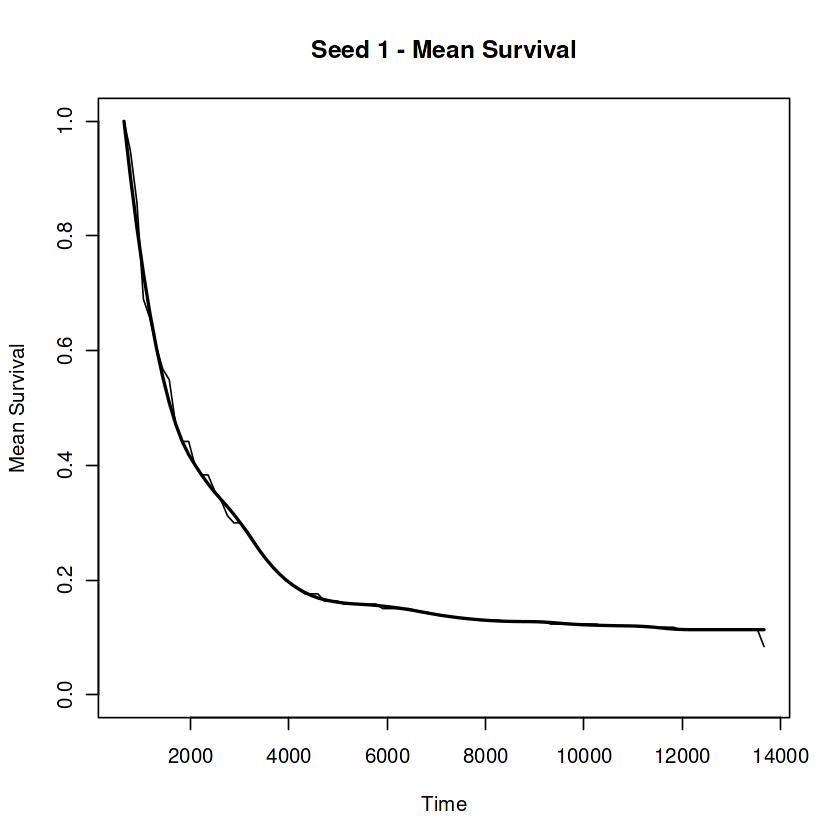


Seed: 2 | LT: 255.411 | Last event: 13184.74 | Eligible: 17 | Used: 17 


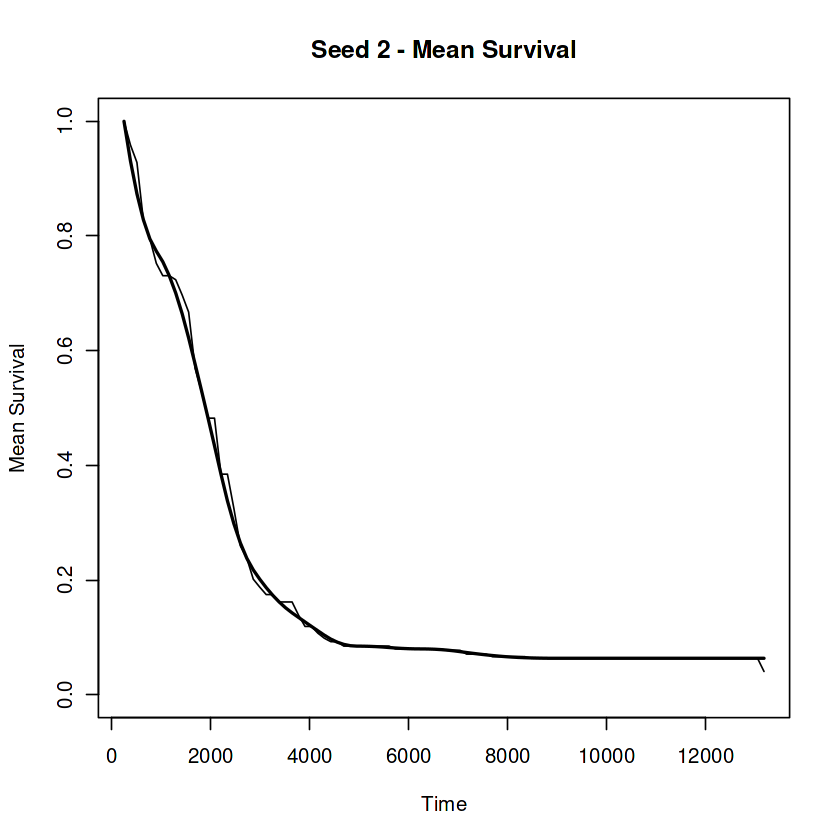


Seed: 3 | LT: 433.665 | Last event: 8976.464 | Eligible: 17 | Used: 13 


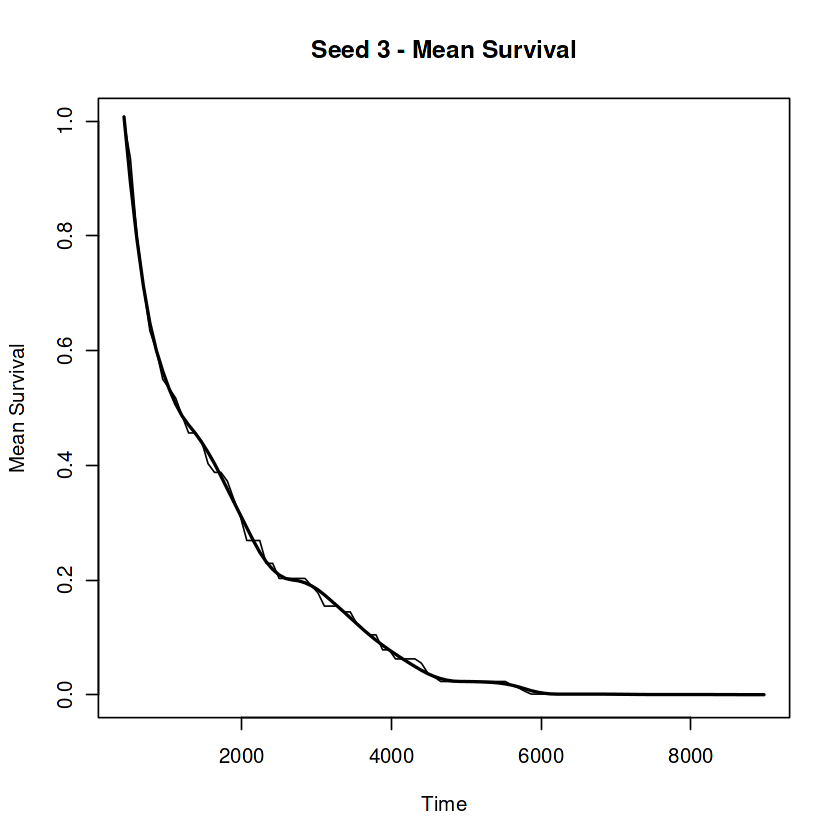


Seed: 4 | LT: 397.195 | Last event: 11345.03 | Eligible: 19 | Used: 16 


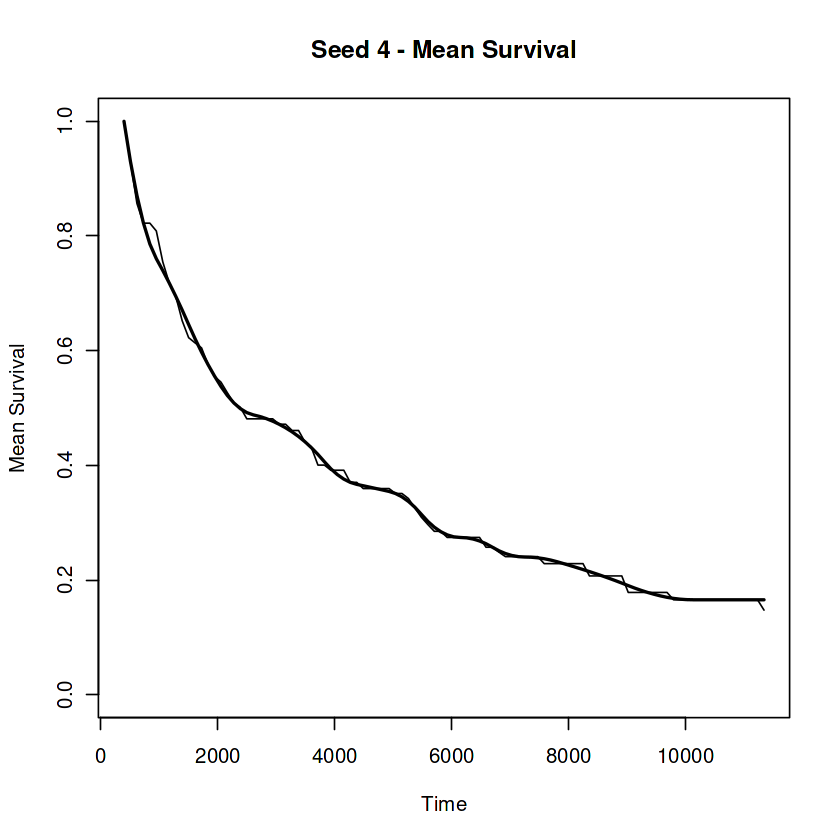


Seed: 5 | LT: 314.466 | Last event: 11004.55 | Eligible: 19 | Used: 18 


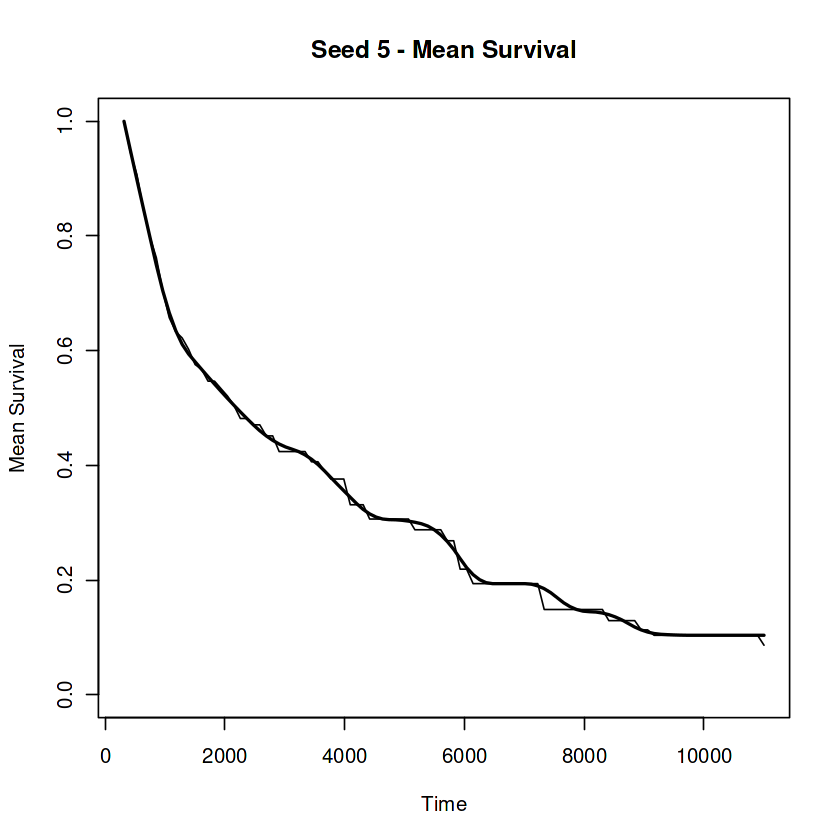

In [28]:
# Mean survival curves for plotting
mean_surv_plot_results <- list()

for (seed in seq_len(5)) {
  # Load files and get data
  train_data <- train_prepared[[seed]]
  test_data <- test_prepared[[seed]]

  fit <- readRDS(file.path(
    models_path,
    paste0("mjoint_fit_seed_", seed,
           "_with_num_", num_traj,
           "_and_timeout_", timeout,
           "_missing.rds")
  ))

  train_surv_times <- train_data %>%
    dplyr::distinct(id, .keep_all = TRUE) %>%
    dplyr::pull(time)

  LT <- quantile(train_surv_times, probs = 0.10, names = FALSE)

  train_subjects <- train_data %>%
    dplyr::distinct(id, time, event)

  last_event_time <- max(train_subjects$time[train_subjects$event == 1])

  pred_times_plot <- seq(LT, last_event_time, length.out = 100)[-1]

  eligible_ids <- test_data %>%
    dplyr::distinct(id, time, event) %>%
    dplyr::filter(time > LT) %>%
    dplyr::pull(id)

  seed_surv_plot_results <- list()
    
  for (pid in eligible_ids) {
  
  # Prepare subject
    one_subject <- test_data %>%
      dplyr::filter(id == pid) %>%
      dplyr::arrange(obstime)

    history <- one_subject %>%
      dplyr::filter(obstime <= LT)

    history_Y1 <- history %>% dplyr::filter(!is.na(Y1))
    history_Y2 <- history %>% dplyr::filter(!is.na(Y2))
    history_Y3 <- history %>% dplyr::filter(!is.na(Y3))

    if (nrow(history_Y1) == 0 ||
        nrow(history_Y2) == 0 ||
        nrow(history_Y3) == 0) next

    last_obs_time <- max(
      max(history_Y1$obstime),
      max(history_Y2$obstime),
      max(history_Y3$obstime)
    )

    # Calculate the surv prob. and cond. prob. to account for survival up to LT
    if (last_obs_time < LT) {

      pred_surv_LT <- tryCatch(
        dynSurv(
          object = fit,
          newdata = list(history_Y1, history_Y2, history_Y3),
          u = LT
        ),
        error = function(e) NULL
      )

      if (is.null(pred_surv_LT)) next

      surv_LT <- as.numeric(pred_surv_LT$pred$surv)

    } else {
      # In this case we have last_obs_time = LT and survival at LT is then 1 
      surv_LT <- 1
    }

    patient_surv_plot <- list()
    # For each patient we predict now the survival
    for (prediction_time in pred_times_plot) {

      pred_surv <- tryCatch(
        dynSurv(
          object = fit,
          newdata = list(history_Y1, history_Y2, history_Y3),
          u = prediction_time
        ),
        error = function(e) NULL
      )

      if (is.null(pred_surv)) next

      predicted_survival <- as.numeric(pred_surv$pred$surv) / surv_LT

      patient_surv_plot[[length(patient_surv_plot) + 1]] <- data.frame(
        seed = seed,
        id = pid,
        prediction_time = prediction_time,
        predicted_survival = predicted_survival
      )
    }

    patient_surv_df <- dplyr::bind_rows(patient_surv_plot)
    
    # Save only plots that have everywhere predictions
    if (nrow(patient_surv_df) == length(pred_times_plot)) {
      seed_surv_plot_results[[length(seed_surv_plot_results) + 1]] <- patient_surv_df
    } else {
      cat(
        "Seed:", seed,
        "| Patient:", pid,
        "| Predictions:", nrow(patient_surv_df),
        "of", length(pred_times_plot),
        "| Missing:", length(pred_times_plot) - nrow(patient_surv_df),
        "\n"
      )
    }
  }

  seed_surv_plot_df <- dplyr::bind_rows(seed_surv_plot_results)

  mean_surv_plot <- seed_surv_plot_df %>%
    dplyr::group_by(prediction_time) %>%
    dplyr::summarise(
      mean_surv = mean(predicted_survival),
      .groups = "drop"
    ) %>%
    dplyr::mutate(seed = seed, .before = 1)

  # Add LT with survival probability 1 for smoothing
  smooth_data <- dplyr::bind_rows(
    data.frame(
      seed = seed,
      prediction_time = LT,
      mean_surv = 1
    ),
    mean_surv_plot
  )


  # Smooth mean survival curve
  smooth_fit <- cobs::cobs(
    x = smooth_data$prediction_time,
    y = smooth_data$mean_surv,
    constraint = "decrease",
    lambda = 1
  )

  smooth_data$mean_surv_smooth <- predict(
    smooth_fit,
    z = smooth_data$prediction_time
  )[, 2]

  mean_surv_plot_results[[seed]] <- mean_surv_plot

  plot(
    smooth_data$prediction_time,
    smooth_data$mean_surv,
    type = "l",
    xlab = "Time",
    ylab = "Mean Survival",
    main = paste0("Seed ", seed, " - Mean Survival"),
    ylim = c(0, 1)
  )
    
  lines(
    smooth_data$prediction_time,
    smooth_data$mean_surv_smooth,
    lwd = 2
  )

  write.csv(
    mean_surv_plot,
    file.path(results_path, paste0("mean_surv_joinerml_seed_", seed, ".csv")),
    row.names = FALSE
  )
  write.csv(
    smooth_data,
    file.path(results_path, paste0("mean_surv_smooth_joinerml_seed_", seed, ".csv")),
    row.names = FALSE
  )

  cat(
    "\nSeed:", seed,
    "| LT:", round(LT, 3),
    "| Last event:", round(last_event_time, 3),
    "| Eligible:", length(eligible_ids),
    "| Used:", length(seed_surv_plot_results),
    "\n"
  )

  rm(train_data, test_data, fit, seed_surv_plot_results, seed_surv_plot_df)
  gc()
}

In [ ]:
# Archiv

In [ ]:
cat("\nSeed:", seed, "\n")
print(brier_result)

cat("NaN in Brier Scores:",
    any(is.nan(brier_result$brier_score)), "\n")

cat("NA in Brier Scores:",
    any(is.na(brier_result$brier_score)), "\n")

cat("Inf in Brier Scores:",
    any(is.infinite(brier_result$brier_score)), "\n")

cat("Prediction times:\n")
print(brier_result$prediction_time)